# Prediksi Kecelakaan Lalu Lintas
---
## 1. Business Understanding

### 1.1 Latar belakang, masalah, dan solusi
1. **Latar Belakang**: Instansi pengelola lalu lintas, kepolisian, dan otoritas keselamatan jalan raya ingin memprediksi potensi terjadinya kecelakaan lalu lintas (Accident) berdasarkan kondisi lingkungan, karakteristik jalan, kendaraan, serta profil pengemudi.
2. **Masalah**: Instansi  pengelola lalu lintas, kepolisian, dan otoritas keselamatan jalan raya membutuhkan sistem untuk memprediksi sistem potensi terjadinya kecelakaan lalu lintas berdasarkan kondisi lingkungan, akrakteristik jalan, kendaraan, serta    profil pengemudi untuk mendukung deteksi resiko dini.
3. **Solusi**: Membangun model *machine learning* dengan algoritma **LightGBM** dengan memanfaatkan data historis lalu lintas untuk membantu deteksi resiko dini, penempatan patroli, serta rekayasa lalu lintas yang lebih baik.

### 1.2 Deskripsi Kolom Dataset `dataset_traffic_accident_prediction1.csv`
| **Nama Kolom** | **Tipe Data** | **Keterangan** |
| :-- | :-- | :-- |
| `Weather` | `str` | cuaca saat ini |
| `Road_Type` | `str` | jenis jalan |
| `Time_of_Day` | `str` | waktu kejadian |
| `Traffic_Density` | `float64` | kepadatan lalu lintas |
| `Speed_Limit` | `float64` | batas kecepatan jalan |
| `Number_of_Vehicles` | `float64` | jumlah kendaraan yang terlibat |
| `Driver_Alcohol` | `float64` | status alkohol pengemudi |
| `Accident_Severity` | `str` | tingkat keparahan kecelakaan |
| `Road_Condition` | `str` | kondisi permukaan jalan |
| `Vehicle_Type` | `str` | tipe kendaraan |
| `Driver_Age` | `float64` | umur pengemudi |
| `Driver_Experience` | `float64` | pengalamanm mengemudi |
| `Road_Light_Condition` | `str` | kondisi pencahayaan jalan |
| `Accident` | `float64` | target klasifikasi (0.0 = tidak terjadi kecelakaan, 1.0 = terjadi kecelakaan) |

---
## 2. Data Preparation

### 2.1 Import library

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

### 2.2 Load dataset

In [2]:
df = pd.read_csv('dataset_traffic_accident_prediction1.csv', na_values=['NA', 'N/A', '', ' '])
df.columns = df.columns.str.strip()

### 2.3 Menampilkan data teratas dan data terbawah

In [3]:
df.head()

,Weather,Road_Type,Time_of_Day,Traffic_Density,Speed_Limit,Number_of_Vehicles,Driver_Alcohol,Accident_Severity,Road_Condition,Vehicle_Type,Driver_Age,Driver_Experience,Road_Light_Condition,Accident
0,Rainy,City Road,Morning,1.0,100.0,5.0,0.0,NaN,Wet,Car,51.0,48.0,Artificial Light,0.0
1,Clear,Rural Road,Night,NaN,120.0,3.0,0.0,Moderate,Wet,Truck,49.0,43.0,Artificial Light,0.0
2,Rainy,Highway,Evening,1.0,60.0,4.0,0.0,Low,Icy,Car,54.0,52.0,Artificial Light,0.0
3,Clear,City Road,Afternoon,2.0,60.0,3.0,0.0,Low,Under Construction,Bus,34.0,31.0,Daylight,0.0
4,Rainy,Highway,Morning,1.0,195.0,11.0,0.0,Low,Dry,Car,62.0,55.0,Artificial Light,1.0


In [4]:
df.tail()

,Weather,Road_Type,Time_of_Day,Traffic_Density,Speed_Limit,Number_of_Vehicles,Driver_Alcohol,Accident_Severity,Road_Condition,Vehicle_Type,Driver_Age,Driver_Experience,Road_Light_Condition,Accident
835,Clear,Highway,Night,2.0,30.0,4.0,0.0,Low,Dry,Car,23.0,15.0,Daylight,0.0
836,Rainy,Rural Road,Evening,2.0,60.0,4.0,0.0,Low,Dry,Motorcycle,52.0,46.0,Daylight,1.0
837,Foggy,Highway,Evening,NaN,30.0,4.0,1.0,High,Dry,Car,NaN,34.0,Artificial Light,NaN
838,Foggy,Highway,Afternoon,2.0,60.0,3.0,0.0,Low,Dry,Car,25.0,19.0,Artificial Light,0.0
839,Clear,Highway,Afternoon,1.0,60.0,4.0,0.0,Low,Dry,Motorcycle,29.0,21.0,Artificial Light,0.0


### 2.4 Menampilkan informasi data

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 840 entries, 0 to 839
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Weather               798 non-null    str    
 1   Road_Type             798 non-null    str    
 2   Time_of_Day           798 non-null    str    
 3   Traffic_Density       798 non-null    float64
 4   Speed_Limit           798 non-null    float64
 5   Number_of_Vehicles    798 non-null    float64
 6   Driver_Alcohol        798 non-null    float64
 7   Accident_Severity     798 non-null    str    
 8   Road_Condition        798 non-null    str    
 9   Vehicle_Type          798 non-null    str    
 10  Driver_Age            798 non-null    float64
 11  Driver_Experience     798 non-null    float64
 12  Road_Light_Condition  798 non-null    str    
 13  Accident              798 non-null    float64
dtypes: float64(7), str(7)
memory usage: 92.0 KB


### 2.5 Memeriksa jumlah data, missing value, dan data duplikat

In [6]:
print(f'jumlah data: {df.size}')
print(f'\njumlah missing value: {df.isnull().sum().sum()}')
print(f'--- missing value setipa kolom --- \n{df.isnull().sum()[df.isnull().sum() > 0]}')

print(f'\njumlah data duplikat: {df.duplicated().sum()}')

jumlah data: 11760

jumlah missing value: 588
--- missing value setipa kolom --- 
Weather                 42
Road_Type               42
Time_of_Day             42
Traffic_Density         42
Speed_Limit             42
Number_of_Vehicles      42
Driver_Alcohol          42
Accident_Severity       42
Road_Condition          42
Vehicle_Type            42
Driver_Age              42
Driver_Experience       42
Road_Light_Condition    42
Accident                42
dtype: int64

jumlah data duplikat: 14


---
## 3. Exploratory Data Analysis (EDA)

### 3.1 Menampilkan deskripsi data

In [7]:
df.describe()

,Traffic_Density,Speed_Limit,Number_of_Vehicles,Driver_Alcohol,Driver_Age,Driver_Experience,Accident
count,798.000000,798.000000,798.000000,798.000000,798.000000,798.000000,798.000000
mean,1.001253,71.050125,3.286967,0.160401,43.259398,38.981203,0.299499
std,0.784894,32.052458,2.017267,0.367208,15.129856,15.273201,0.458326
min,0.000000,30.000000,1.000000,0.000000,18.000000,9.000000,0.000000
25%,0.000000,50.000000,2.000000,0.000000,30.000000,26.000000,0.000000
50%,1.000000,60.000000,3.000000,0.000000,43.000000,39.000000,0.000000
75%,2.000000,80.000000,4.000000,0.000000,56.000000,52.750000,1.000000
max,2.000000,213.000000,14.000000,1.000000,69.000000,69.000000,1.000000


### 3.2 Analisis outlier dengan IQR dan Z-Score

In [8]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
outliers = []

for col in numeric_cols:
    if col in df.columns:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        lower = q1 - (1.5 * iqr)
        upper = q3 + (1.5 * iqr)
        mean = df[col].mean()
        median = df[col].median()
        std = df[col].std()
        skew = df[col].skew()
        min = df[col].min()
        max = df[col].max()
        z_score = (df[col] - mean) / std
        outlier_iqr = df[(df[col] < lower) | (df[col] > upper)]
        outlier_z = df[np.abs(z_score) > 3]
        
        outliers.append({
            'nama kolom': col,
            'mean': mean,
            'stnadard deviasi': std,
            'kemiringan': skew,
            'min': min,
            'q1': q1,
            'median': median,
            'q3': q3,
            'max': max,
            'oulier iqr': outlier_iqr.shape[0],
            'outlier z-score': outlier_z.shape[0]
        })
        
pd.DataFrame(outliers)

,nama kolom,mean,stnadard deviasi,kemiringan,min,q1,median,q3,max,oulier iqr,outlier z-score
0,Traffic_Density,1.001253,0.784894,-0.002200,0.0,0.0,1.0,2.00,2.0,0,0
1,Speed_Limit,71.050125,32.052458,1.853672,30.0,50.0,60.0,80.00,213.0,25,25
2,Number_of_Vehicles,3.286967,2.017267,2.125287,1.0,2.0,3.0,4.00,14.0,23,23
3,Driver_Alcohol,0.160401,0.367208,1.854276,0.0,0.0,0.0,0.00,1.0,128,0
4,Driver_Age,43.259398,15.129856,0.062291,18.0,30.0,43.0,56.00,69.0,0,0
5,Driver_Experience,38.981203,15.273201,0.006514,9.0,26.0,39.0,52.75,69.0,0,0
6,Accident,0.299499,0.458326,0.877127,0.0,0.0,0.0,1.00,1.0,0,0


### 3.3 Visualisasi outlier dengan boxplot

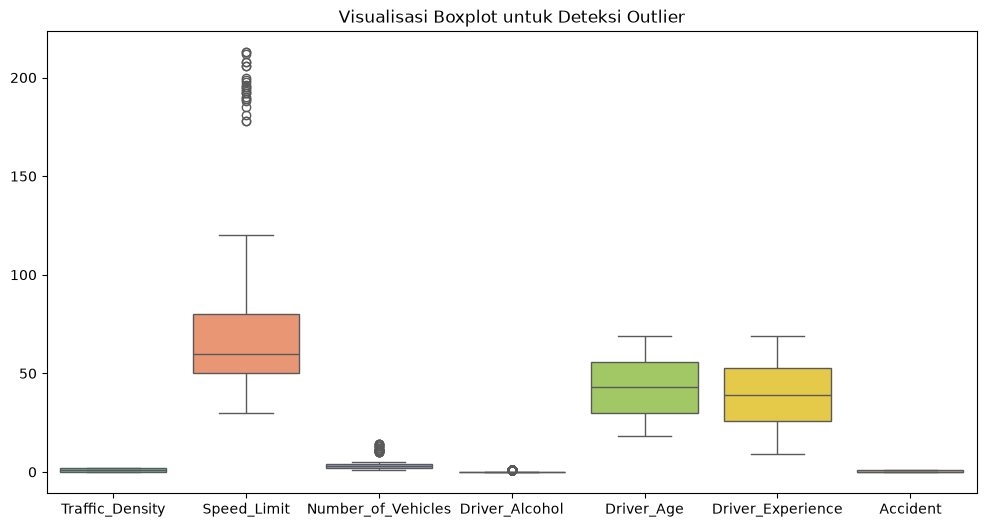

In [9]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[numeric_cols], palette='Set2')
plt.title('Visualisasi Boxplot untuk Deteksi Outlier')
plt.show()

**Insight**: pencilan (*outlier*) pada batas atas fitur `Speed_Limit` dan `Number_of_Vehicles` serta perbedaan rentang skala antarvariabel, sementara `Driver_Age` dan `Driver_Experience` terdistribusi merata tanpa pencilan.

### 3.4 Visualisasi distribusi kolom numerik

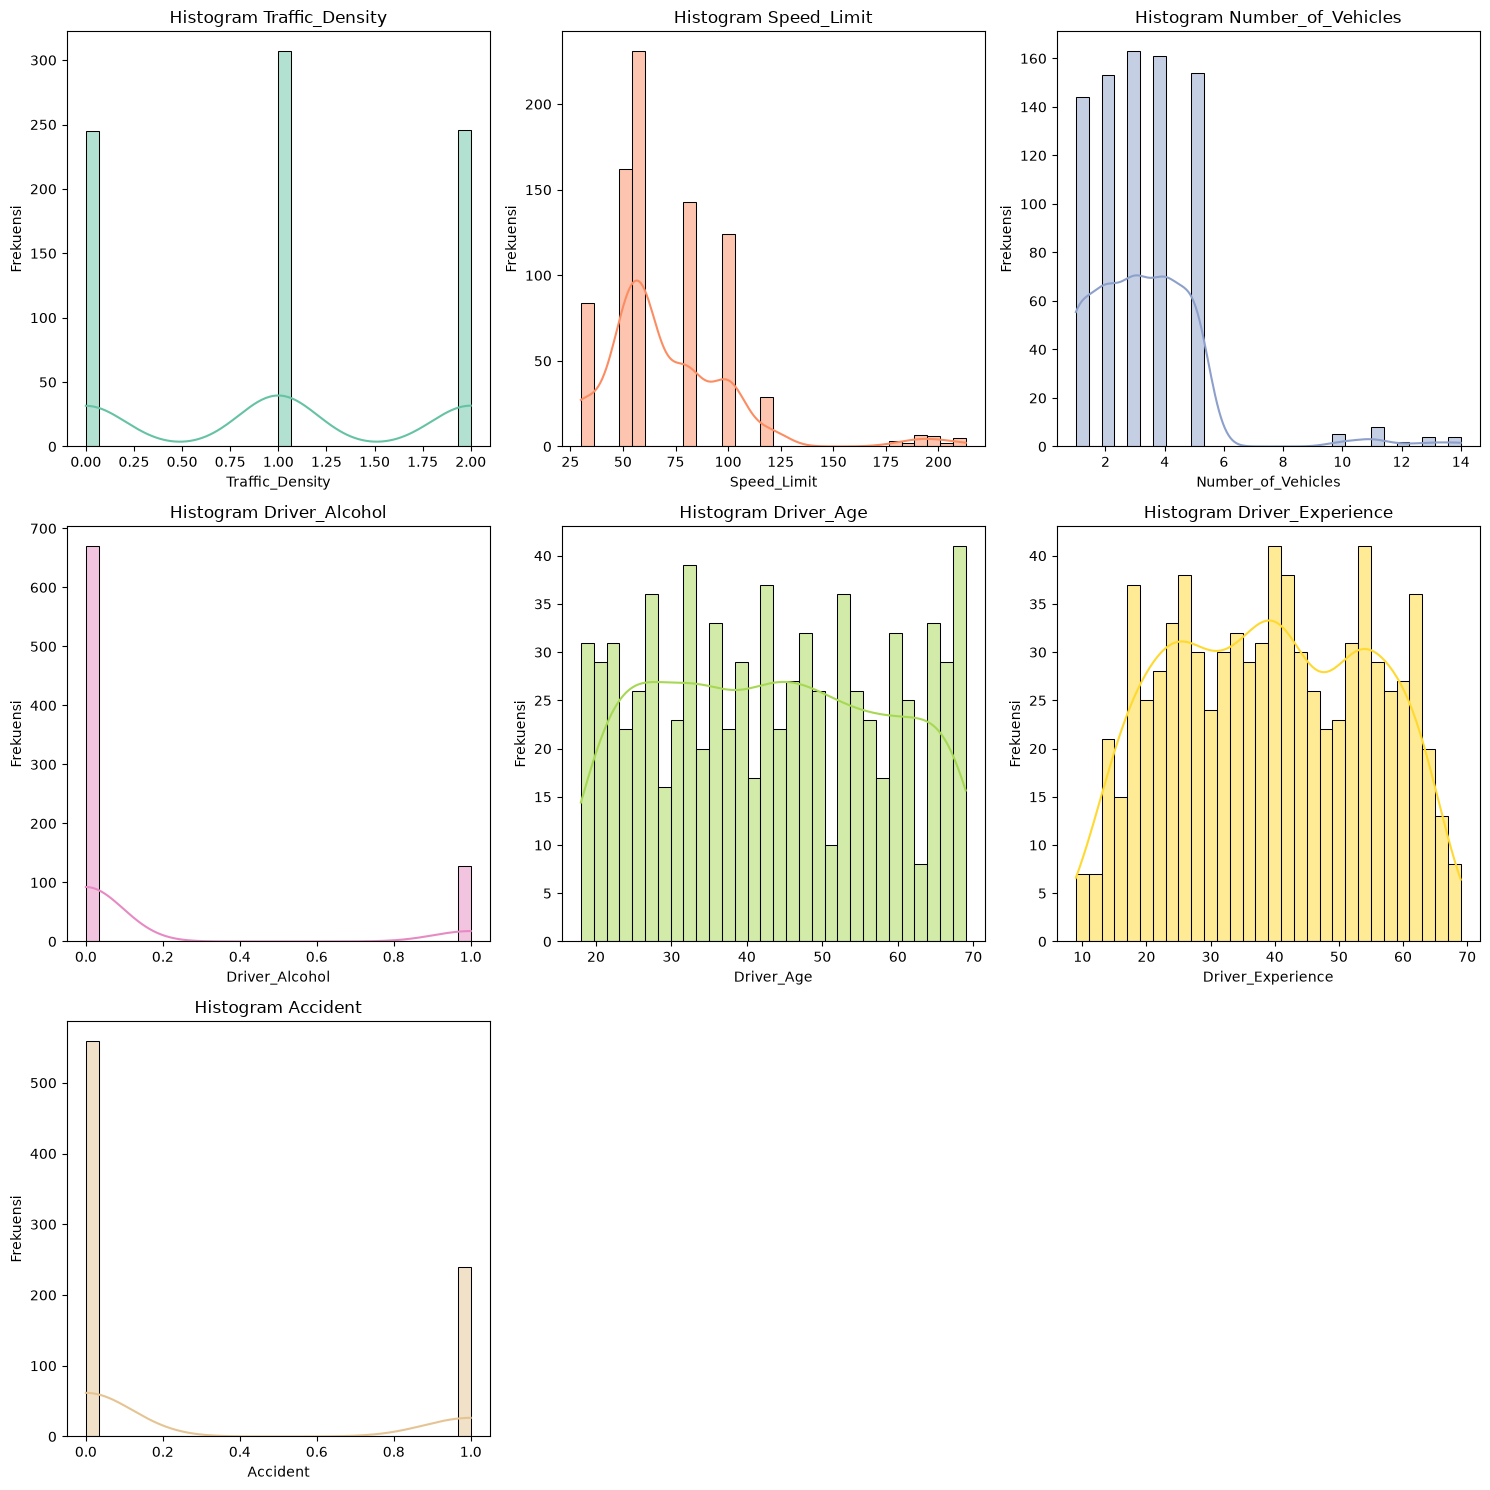

In [10]:
n_cols = 3
n_rows = int(len(numeric_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5 * n_rows))
axes = axes.flatten()
colors = sns.color_palette('Set2', len(numeric_cols))

for i, col in enumerate(numeric_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=axes[i], color=colors[i])
    axes[i].set_title(f'Histogram {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frekuensi')

for i in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

**Insight**: Histogram tersebut menunjukkan bahwa fitur `Speed_Limit` dan `Number_of_Vehicles` memiliki distribusi miring ke kanan akibat nilai ekstrem atas, `Driver_Age` dan `Driver_Experience` tersebar relatif merata, sedangkan `Driver_Alcohol` serta variabel target `Accident` mengalami ketimpangan kelas yang didominasi oleh nilai 0.

### 3.5 Analisis korelasi matrik kolom numerik

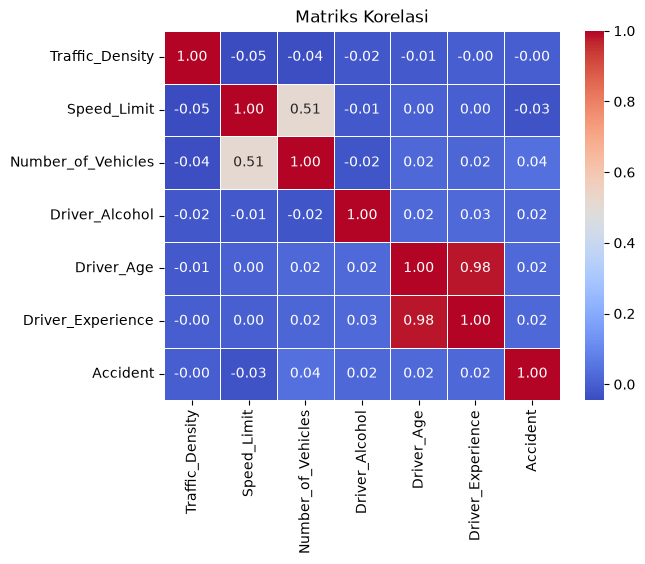

In [11]:
korelsi = df[numeric_cols].corr(method='pearson')
sns.heatmap(korelsi, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Matriks Korelasi')
plt.show()

**Insight**: Matriks korelasi tersebut menunjukkan hubungan linear yang sangat kuat antara `Driver_Age` dan `Driver_Experience` (0,98) serta korelasi sedang antara `Speed_Limit` dan `Number_of_Vehicles` (0,51)

### 3.6 Distribusi Kolom Kategorikal

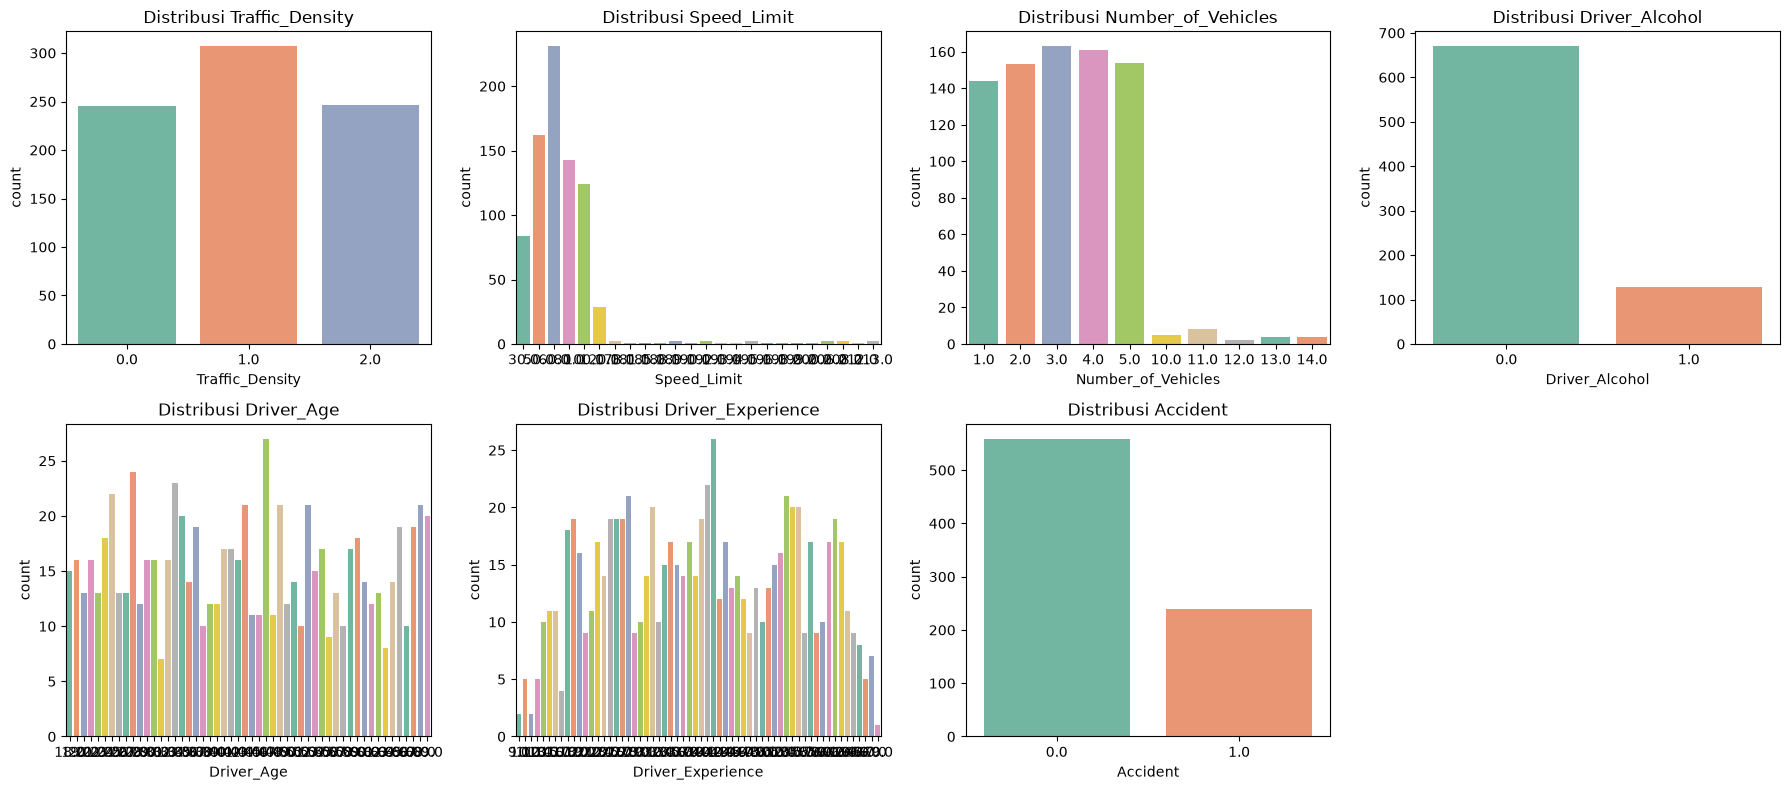

In [12]:
columns = ['Weather', 'Road_Type', 'Time_of_Day', 'Traffic_Density', 'Speed_Limit', 'Road_Condition', 'Vehicle_Type', 'Road_Light_Condition', 'Accident']
n_cols = 4
n_rows = int(len(numeric_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
axes = axes.flatten()
colors = sns.color_palette('Set2', len(numeric_cols))

for i, col in enumerate(numeric_cols):
    sns.countplot(data=df, x=col, ax=axes[i], palette='Set2', hue=col,  legend=False)
    axes[i].set_title(f'Distribusi {col}')

for i in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

**Insight**: Visualisasi diagram batang tersebut menunjukkan bahwa frekuensi `Speed_Limit` dan `Number_of_Vehicles` terkonsentrasi pada rentang rendah hingga menengah dengan sedikit kemunculan nilai ekstrem atas, `Traffic_Density`, `Driver_Age`, serta `Driver_Experience` tersebar relatif merata, sedangkan `Driver_Alcohol` dan variabel target `Accident` didominasi oleh kelas 0.0.

---
## 4. Data Preprocessing

### 4.1 Menampilkan kembali missing value dan data duplikat

In [13]:
print(f'-- missing value =-- \n{df.isnull().sum()[df.isnull().sum() > 0]}')
print(f'\njumlah data duplikat = {df.duplicated().sum()}')

-- missing value =-- 
Weather                 42
Road_Type               42
Time_of_Day             42
Traffic_Density         42
Speed_Limit             42
Number_of_Vehicles      42
Driver_Alcohol          42
Accident_Severity       42
Road_Condition          42
Vehicle_Type            42
Driver_Age              42
Driver_Experience       42
Road_Light_Condition    42
Accident                42
dtype: int64

jumlah data duplikat = 14


### 4.2 Menghapus missing value pada kolom target

In [14]:
df = df.drop_duplicates().dropna(subset=['Accident']).reset_index(drop=True)

print(f'jumlah data setelah pembersihan: {df.shape}')

jumlah data setelah pembersihan: (784, 14)


### 4.3 Memisahkan kolom fitur($X$) dan kolom target($y$)

In [15]:
X = df.drop(columns=['Accident'])
y = df['Accident'].astype('int')

### 4.4 Spliting data

In [16]:
np.random.seed(42)
idx_train_list, idx_test_list = [], []

for kelas in np.unique(y):
    idx_kelas = np.where(y == kelas)[0]
    idx_acak = np.random.permutation(idx_kelas)
    batas = int(0.8 * len(idx_acak))
    idx_train_list.append(idx_acak[:batas])
    idx_test_list.append(idx_acak[batas:])

idx_train = np.random.permutation(np.concatenate(idx_train_list))
idx_test = np.random.permutation(np.concatenate(idx_test_list))

X_train = X.iloc[idx_train].copy().reset_index(drop=True)
X_test = X.iloc[idx_test].copy().reset_index(drop=True)
y_train = y.iloc[idx_train].reset_index(drop=True)
y_test = y.iloc[idx_test].reset_index(drop=True)

print(f'jumlah data train: {X_train.shape[0]} baris, {X_train.shape[1]} kolom')
print(f'jumlah data test: {y_test.shape[0]}')

jumlah data train: 627 baris, 13 kolom
jumlah data test: 157


### 4.5 Penanganan missing value pada kolom numerik dan kategorikal

In [17]:
kolom_kategorikal = ['Weather', 'Road_Type', 'Time_of_Day', 'Traffic_Density', 'Driver_Alcohol', 'Accident_Severity', 'Road_Condition', 'Vehicle_Type', 'Road_Light_Condition']
kolom_numerik = ['Speed_Limit', 'Number_of_Vehicles', 'Driver_Age', 'Driver_Experience']

for col in kolom_kategorikal:
    X_train[col] = X_train[col].fillna(X_train[col].mode()[0])
    X_test[col] = X_test[col].fillna(X_train[col].mode()[0])
    
for col in kolom_numerik:
    X_train[col] = X_train[col].fillna(X_train[col].median())
    X_test[col] = X_test[col].fillna(X_train[col].median())
    
print(f'-- missing value -- \n{X_train.isnull().sum()[X_train.isnull().sum() > 0]}')

-- missing value -- 
Series([], dtype: int64)


### 4.6 Penangan outlier

In [18]:
for col in ['Speed_Limit', 'Number_of_Vehicles']:
    q1 = X_train[col].quantile(0.25)
    q3 = X_train[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    X_train[col] = np.clip(X_train[col], lower, upper)
    X_test[col] = np.clip(X_test[col], lower, upper)

### 4.7 Encoding fitur kategorikal

In [19]:
map_saverity = {'Low': 0, 'Moderate': 1, 'High': 2}
map_light = {'No Light': 0, 'Artificial Light': 1, 'Daylight': 2}
kolom_nominal = ['Weather', 'Road_Type', 'Time_of_Day', 'Road_Condition', 'Vehicle_Type']

X_train['Accident_Severity'] = X_train['Accident_Severity'].map(map_saverity)
X_test['Accident_Severity'] = X_test['Accident_Severity'].map(map_saverity)

X_train['Road_Light_Condition'] = X_train['Road_Light_Condition'].map(map_light)
X_test['Road_Light_Condition'] = X_test['Road_Light_Condition'].map(map_light)


X_train = pd.get_dummies(X_train, columns=kolom_nominal, drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, columns=kolom_nominal, drop_first=True, dtype=int)

X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

X_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 627 entries, 0 to 626
Data columns (total 24 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Traffic_Density                    627 non-null    float64
 1   Speed_Limit                        627 non-null    float64
 2   Number_of_Vehicles                 627 non-null    float64
 3   Driver_Alcohol                     627 non-null    float64
 4   Accident_Severity                  627 non-null    int64  
 5   Driver_Age                         627 non-null    float64
 6   Driver_Experience                  627 non-null    float64
 7   Road_Light_Condition               627 non-null    int64  
 8   Weather_Foggy                      627 non-null    int64  
 9   Weather_Rainy                      627 non-null    int64  
 10  Weather_Snowy                      627 non-null    int64  
 11  Weather_Stormy                     627 non-null    int64  
 12  Road_

### 4.8 Scaling kolom dengan standarization

In [20]:
for col in kolom_numerik:
    mean = X_train[col].mean()
    std = X_train[col].std()
    X_train[col] = (X_train[col] - mean) / std
    X_test[col] = (X_test[col] - mean) / std

X_train_np = X_train.to_numpy(dtype=float)
X_test_np = X_test.to_numpy(dtype=float)
y_train_np = y_train.to_numpy(dtype=float)
y_test_np = y_test.to_numpy(dtype=float)

df.describe()

,Traffic_Density,Speed_Limit,Number_of_Vehicles,Driver_Alcohol,Driver_Age,Driver_Experience,Accident
count,744.000000,743.000000,746.000000,744.000000,744.000000,743.000000,784.000000
mean,1.009409,71.130552,3.297587,0.161290,43.383065,39.161507,0.298469
std,0.789342,32.257646,2.023996,0.368046,15.164146,15.291887,0.457879
min,0.000000,30.000000,1.000000,0.000000,18.000000,9.000000,0.000000
25%,0.000000,50.000000,2.000000,0.000000,30.000000,26.000000,0.000000
50%,1.000000,60.000000,3.000000,0.000000,43.000000,39.000000,0.000000
75%,2.000000,80.000000,4.000000,0.000000,56.000000,53.000000,1.000000
max,2.000000,213.000000,14.000000,1.000000,69.000000,69.000000,1.000000


<Axes: >

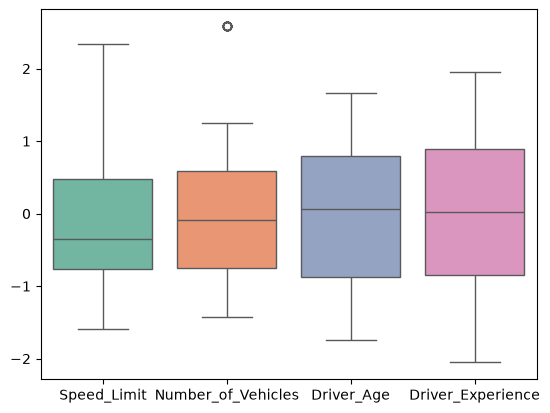

In [21]:
sns.boxplot(data=X_train[kolom_numerik], palette='Set2')

**Insight**: Grafik boxplot tersebut menunjukkan bahwa keempat fitur numerik kini memiliki rentang skala yang seragam di sekitar nilai tengah nol serta bebas dari pencilan ekstrem sehingga siap digunakan untuk tahap pemodelan.

---

## 5. Modelling

### 5.1 Membangun Algoritma

In [22]:
class LightGBM:
    def __init__(self, n_estimators=100, learning_rate=0.05, max_depth=5, num_leaves=15,
                 min_child_samples=10, max_bins=64, lambda_reg=1.0, scale_pos_weight=1.0):
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.max_depth = max_depth
        self.num_leaves = num_leaves
        self.min_child_samples = min_child_samples
        self.max_bins = max_bins
        self.lambda_reg = lambda_reg
        self.scale_pos_weight = scale_pos_weight

    def sigmoid(self, x):
        return 1 / (1 + np.exp(-np.clip(x, -500, 500)))

    def buat_bin(self, X):
        X_bin = np.zeros(X.shape, dtype=int)
        self.thresholds = []
        kuantil = np.linspace(0, 1, self.max_bins + 1)[1:-1]

        for j in range(X.shape[1]):
            nilai_unik = np.unique(X[:, j])
            if len(nilai_unik) <= self.max_bins:
                batas = (nilai_unik[:-1] + nilai_unik[1:]) / 2
            else:
                batas = np.unique(np.quantile(X[:, j], kuantil))
            self.thresholds.append(batas)
            X_bin[:, j] = np.searchsorted(batas, X[:, j])

        return X_bin

    def cari_split(self, idx, X_bin, g, h):
        if len(idx) < 2 * self.min_child_samples:
            return None

        G = g[idx].sum()
        H = h[idx].sum()
        gain_terbaik = 0.0
        hasil = None

        for j, batas in enumerate(self.thresholds):
            if len(batas) == 0:
                continue

            bins = X_bin[idx, j]
            ukuran = len(batas) + 1
            g_kiri = np.cumsum(np.bincount(bins, weights=g[idx], minlength=ukuran))[:-1]
            h_kiri = np.cumsum(np.bincount(bins, weights=h[idx], minlength=ukuran))[:-1]
            c_kiri = np.cumsum(np.bincount(bins, minlength=ukuran))[:-1]

            valid = (c_kiri >= self.min_child_samples) & (len(idx) - c_kiri >= self.min_child_samples)
            if not valid.any():
                continue

            g_kanan = G - g_kiri
            h_kanan = H - h_kiri
            gain = 0.5 * (
                (g_kiri ** 2) / (h_kiri + self.lambda_reg)
                + (g_kanan ** 2) / (h_kanan + self.lambda_reg)
                - (G ** 2) / (H + self.lambda_reg)
            )

            k = np.argmax(np.where(valid, gain, -np.inf))
            if gain[k] > gain_terbaik:
                gain_terbaik = gain[k]
                hasil = (gain[k], j, k, batas[k])

        return hasil

    def bangun_pohon(self, X_bin, g, h):
        idx = np.arange(len(g))
        nilai_root = -g[idx].sum() / (h[idx].sum() + self.lambda_reg)
        root = {"value": nilai_root, "depth": 0}

        split_awal = self.cari_split(idx, X_bin, g, h)
        kandidat = [(split_awal, root, idx)] if split_awal else []
        jumlah_daun = 1

        while kandidat and jumlah_daun < self.num_leaves:
            idx_terbaik = np.argmax([item[0][0] for item in kandidat])
            split, node, n_idx = kandidat.pop(idx_terbaik)
            _, fitur, cut_bin, thresh = split

            mask = X_bin[n_idx, fitur] <= cut_bin
            node["feature"] = fitur
            node["threshold"] = thresh

            for sisi, anak_idx in [("left", n_idx[mask]), ("right", n_idx[~mask])]:
                nilai_anak = -g[anak_idx].sum() / (h[anak_idx].sum() + self.lambda_reg)
                node[sisi] = {"value": nilai_anak, "depth": node["depth"] + 1}

                if node[sisi]["depth"] < self.max_depth:
                    s = self.cari_split(anak_idx, X_bin, g, h)
                    if s:
                        kandidat.append((s, node[sisi], anak_idx))

            jumlah_daun += 1

        return root

    def prediksi_pohon(self, node, X):
        if "feature" not in node:
            return np.full(len(X), node["value"])

        mask = X[:, node["feature"]] <= node["threshold"]
        out = np.zeros(len(X))
        if mask.any():
            out[mask] = self.prediksi_pohon(node["left"], X[mask])
        if (~mask).any():
            out[~mask] = self.prediksi_pohon(node["right"], X[~mask])
        return out

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        bobot = np.where(y == 1, self.scale_pos_weight, 1.0)
        X_bin = self.buat_bin(X)

        rasio = np.clip(np.sum(bobot * y) / np.sum(bobot), 1e-15, 1 - 1e-15)
        self.base_score = np.log(rasio / (1 - rasio))
        self.trees = []
        raw = np.full(len(y), self.base_score)

        for _ in range(self.n_estimators):
            p = self.sigmoid(raw)
            g = bobot * (p - y)
            h = np.maximum(bobot * p * (1 - p), 1e-16)

            pohon = self.bangun_pohon(X_bin, g, h)
            self.trees.append(pohon)
            raw += self.learning_rate * self.prediksi_pohon(pohon, X)

        return self

    def predict_prob(self, X):
        X = np.asarray(X, dtype=float)
        skor = np.full(len(X), self.base_score)
        for pohon in self.trees:
            skor += self.learning_rate * self.prediksi_pohon(pohon, X)
        return self.sigmoid(skor)

    def predict(self, X, threshold=0.5):
        return (self.predict_prob(X) >= threshold).astype(int)

### 5.2 Pembagian Data dan Pelatihan Model

In [23]:
def buat_kfold(y, k=5, seed=42):
    np.random.seed(seed)
    bagian = [[] for _ in range(k)]

    for label in np.unique(y):
        idx = np.where(y == label)[0]
        np.random.shuffle(idx)
        for i, potongan in enumerate(np.array_split(idx, k)):
            bagian[i].extend(potongan)

    hasil_fold = []
    for i in range(k):
        val_idx = np.array(bagian[i])
        train_idx = np.concatenate([bagian[j] for j in range(k) if j != i])
        hasil_fold.append((train_idx, val_idx))
    return hasil_fold

pos_weight = np.sum(y_train_np == 0) / np.sum(y_train_np == 1)
folds = buat_kfold(y_train_np, k=5)
models = []
results = []

for i, (train_idx, val_idx) in enumerate(folds, 1):
    model = LightGBM(scale_pos_weight=pos_weight)
    model.fit(X_train_np[train_idx], y_train_np[train_idx])

    y_val = y_train_np[val_idx].astype(int)
    y_prob = model.predict_prob(X_train_np[val_idx])
    y_pred = model.predict(X_train_np[val_idx])

    models.append(model)
    results.append((val_idx, y_val, y_prob, y_pred))
    print(f"Fold {i} | Train: {len(train_idx)} | Val: {len(val_idx)} | Pos Val: {int(y_val.sum())}")

Fold 1 | Train: 501 | Val: 126 | Pos Val: 38
Fold 2 | Train: 501 | Val: 126 | Pos Val: 38
Fold 3 | Train: 502 | Val: 125 | Pos Val: 37
Fold 4 | Train: 502 | Val: 125 | Pos Val: 37
Fold 5 | Train: 502 | Val: 125 | Pos Val: 37


### 5.3 Hyperparameter Tuning

Config 1 | Val Log Loss: 0.7081 | {'n_estimators': 50, 'learning_rate': 0.05, 'num_leaves': 7, 'max_depth': 3, 'lambda_reg': 2.0}
Config 2 | Val Log Loss: 0.7446 | {'n_estimators': 80, 'learning_rate': 0.05, 'num_leaves': 10, 'max_depth': 4, 'lambda_reg': 2.0}
Config 3 | Val Log Loss: 0.7919 | {'n_estimators': 100, 'learning_rate': 0.05, 'num_leaves': 15, 'max_depth': 5, 'lambda_reg': 1.0}
Config 4 | Val Log Loss: 0.7368 | {'n_estimators': 120, 'learning_rate': 0.03, 'num_leaves': 10, 'max_depth': 4, 'lambda_reg': 3.0}


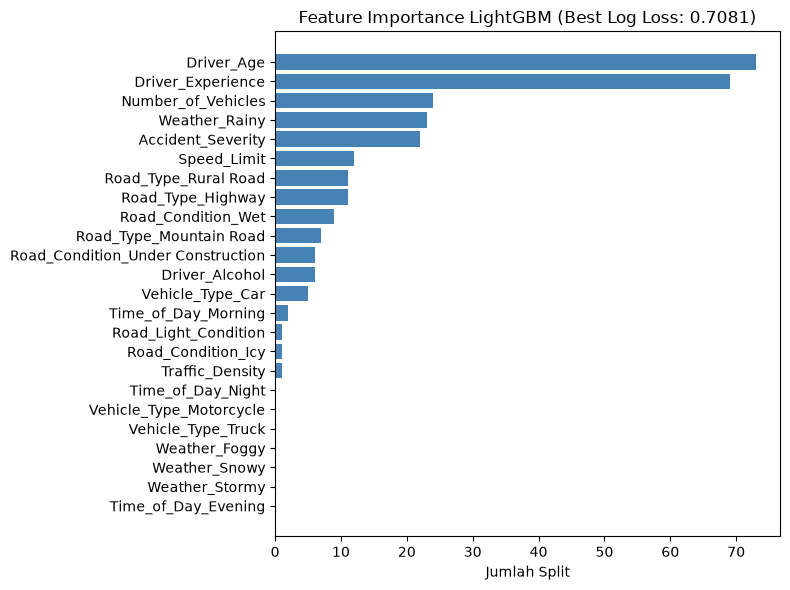

In [24]:
def hitung_log_loss(y_true, y_prob, pos_w=1.0):
    p = np.clip(y_prob, 1e-15, 1 - 1e-15)
    w = np.where(y_true == 1, pos_w, 1.0)
    loss = -np.sum(w * (y_true * np.log(p) + (1 - y_true) * np.log(1 - p))) / np.sum(w)
    return loss

def hitung_split_fitur(trees, jumlah_fitur):
    hitungan = np.zeros(jumlah_fitur, dtype=int)
    tumpukan = list(trees)
    while tumpukan:
        node = tumpukan.pop()
        if "feature" in node:
            hitungan[node["feature"]] += 1
            tumpukan.append(node["left"])
            tumpukan.append(node["right"])
    return hitungan

daftar_param = [
    {"n_estimators": 50,  "learning_rate": 0.05, "num_leaves": 7,  "max_depth": 3, "lambda_reg": 2.0},
    {"n_estimators": 80,  "learning_rate": 0.05, "num_leaves": 10, "max_depth": 4, "lambda_reg": 2.0},
    {"n_estimators": 100, "learning_rate": 0.05, "num_leaves": 15, "max_depth": 5, "lambda_reg": 1.0},
    {"n_estimators": 120, "learning_rate": 0.03, "num_leaves": 10, "max_depth": 4, "lambda_reg": 3.0},
]

best_loss = np.inf
best_params = None
best_models = None
best_results = None

for i, params in enumerate(daftar_param, 1):
    f_models = []
    f_results = []
    daftar_loss = []

    for train_idx, val_idx in folds:
        m = LightGBM(**params, scale_pos_weight=pos_weight)
        m.fit(X_train_np[train_idx], y_train_np[train_idx])

        prob = m.predict_prob(X_train_np[val_idx])
        pred = (prob >= 0.5).astype(int)
        y_val = y_train_np[val_idx].astype(int)

        f_models.append(m)
        f_results.append((val_idx, y_val, prob, pred))
        daftar_loss.append(hitung_log_loss(y_val, prob, pos_weight))

    rata_loss = np.mean(daftar_loss)
    print(f"Config {i} | Val Log Loss: {rata_loss:.4f} | {params}")

    if rata_loss < best_loss:
        best_loss = rata_loss
        best_params = params
        best_models = f_models
        best_results = f_results

models = best_models
results = best_results

oof_prob = np.zeros(len(y_train_np))
oof_pred = np.zeros(len(y_train_np), dtype=int)
for val_idx, _, prob, pred in results:
    oof_prob[val_idx] = prob
    oof_pred[val_idx] = pred

final_model = LightGBM(**best_params, scale_pos_weight=pos_weight)
final_model.fit(X_train_np, y_train_np)

importances = hitung_split_fitur(final_model.trees, X_train_np.shape[1])
urutan = np.argsort(importances)
nama_fitur = np.array(X_train.columns)

plt.figure(figsize=(8, 6))
plt.barh(nama_fitur[urutan], importances[urutan], color="steelblue")
plt.title(f"Feature Importance LightGBM (Best Log Loss: {best_loss:.4f})")
plt.xlabel("Jumlah Split")
plt.tight_layout()
plt.show()

---

## 6. Evaluation

### 6.1 Evaluasi Performa Model

     Fold  Accuracy  Precision  Recall  F1-Score  ROC-AUC     MCC
   Fold 1    0.5397     0.3611  0.6842    0.4727   0.5241  0.1498
   Fold 2    0.4762     0.3158  0.6316    0.4211   0.5640  0.0382
   Fold 3    0.5040     0.2727  0.4054    0.3261   0.5043 -0.0452
   Fold 4    0.5840     0.3684  0.5676    0.4468   0.5708  0.1452
   Fold 5    0.4560     0.2687  0.4865    0.3462   0.4034 -0.0644
Rata-rata    0.5120     0.3173  0.5550    0.4026   0.5133  0.0447
OOF Train    0.5120     0.3180  0.5561    0.4047   0.5115  0.0452
 Test Set    0.5159     0.3371  0.6383    0.4412   0.5572  0.0942


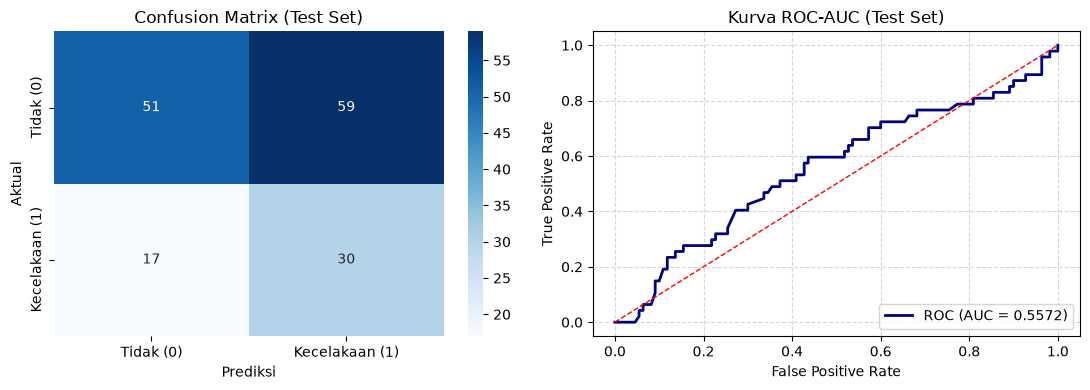

In [25]:
def hitung_roc_auc(y_true, y_prob):
    batas = np.sort(np.unique(y_prob))[::-1]
    batas = np.concatenate(([np.inf], batas))
    pos = np.maximum(np.sum(y_true == 1), 1)
    neg = np.maximum(np.sum(y_true == 0), 1)

    tpr = []
    fpr = []
    for t in batas:
        tpr.append(np.sum((y_prob >= t) & (y_true == 1)) / pos)
        fpr.append(np.sum((y_prob >= t) & (y_true == 0)) / neg)

    tpr = np.array(tpr)
    fpr = np.array(fpr)
    auc = np.sum((fpr[1:] - fpr[:-1]) * (tpr[1:] + tpr[:-1]) / 2)
    return fpr, tpr, auc

def hitung_metrik(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))

    acc = (tp + tn) / len(y_true)
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0

    penyebut = np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    mcc = ((tp * tn) - (fp * fn)) / penyebut if penyebut > 0 else 0.0
    _, _, auc = hitung_roc_auc(y_true, y_prob)

    return {
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "ROC-AUC": auc,
        "MCC": mcc
    }

y_tr_int = y_train_np.astype(int)
y_te_int = y_test_np.astype(int)
test_prob = final_model.predict_prob(X_test_np)
test_pred = final_model.predict(X_test_np)

daftar_hasil = []
for i, (_, y_val, y_prob, _) in enumerate(results, 1):
    baris = {"Fold": f"Fold {i}"}
    baris.update(hitung_metrik(y_val, y_prob))
    daftar_hasil.append(baris)

eval_df = pd.DataFrame(daftar_hasil)

rata_rata = {"Fold": "Rata-rata"}
rata_rata.update(eval_df.drop(columns="Fold").mean().to_dict())

baris_oof = {"Fold": "OOF Train"}
baris_oof.update(hitung_metrik(y_tr_int, oof_prob))

baris_test = {"Fold": "Test Set"}
baris_test.update(hitung_metrik(y_te_int, test_prob))

tambahan = pd.DataFrame([rata_rata, baris_oof, baris_test])
summary_df = pd.concat([eval_df, tambahan], ignore_index=True)
print(summary_df.round(4).to_string(index=False))

cm = np.array([
    [np.sum((y_te_int == 0) & (test_pred == 0)), np.sum((y_te_int == 0) & (test_pred == 1))],
    [np.sum((y_te_int == 1) & (test_pred == 0)), np.sum((y_te_int == 1) & (test_pred == 1))]
])
fpr, tpr, test_auc = hitung_roc_auc(y_te_int, test_prob)
label = ["Tidak (0)", "Kecelakaan (1)"]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=label, yticklabels=label, ax=ax[0])
ax[0].set_title("Confusion Matrix (Test Set)")
ax[0].set_xlabel("Prediksi")
ax[0].set_ylabel("Aktual")

ax[1].plot(fpr, tpr, color="navy", lw=2, label=f"ROC (AUC = {test_auc:.4f})")
ax[1].plot([0, 1], [0, 1], "r--", lw=1)
ax[1].set_title("Kurva ROC-AUC (Test Set)")
ax[1].set_xlabel("False Positive Rate")
ax[1].set_ylabel("True Positive Rate")
ax[1].grid(True, linestyle="--", alpha=0.5)
ax[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

### 6.2 Noise Pertubation Testing

Noise  Accuracy  Precision  Recall  F1-Score  ROC-AUC    MCC  Drop_Acc
   0%    0.5120     0.3180  0.5561    0.4047   0.5115 0.0452    0.0000
   5%    0.5024     0.3123  0.5561    0.4000   0.4997 0.0327    0.0096
  10%    0.5072     0.3163  0.5615    0.4046   0.4908 0.0418    0.0048
  20%    0.4992     0.3046  0.5294    0.3867   0.4998 0.0144    0.0128


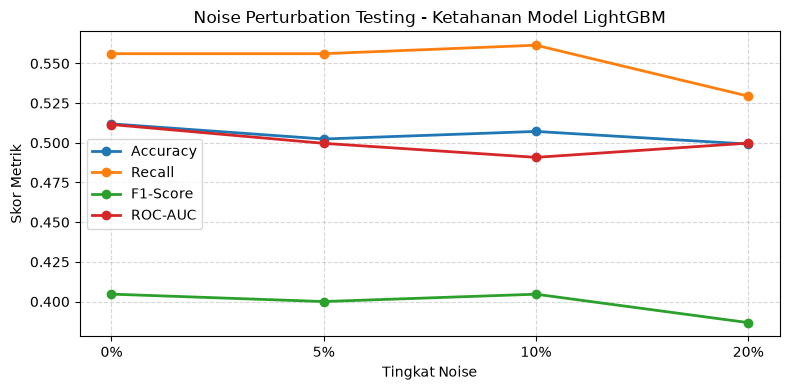

In [26]:
def uji_noise(models, folds, X, y, daftar_noise=[0.0, 0.05, 0.10, 0.20], seed=42):
    rng = np.random.default_rng(seed)
    std_fitur = np.std(X, axis=0)
    hasil = []

    for level in daftar_noise:
        prob_oof = np.zeros(len(y))

        for model, (_, val_idx) in zip(models, folds):
            X_val = X[val_idx].astype(float)
            if level > 0:
                noise = rng.normal(0, level * std_fitur, X_val.shape)
                X_val = X_val + noise
            prob_oof[val_idx] = model.predict_prob(X_val)

        baris = {"Noise": f"{int(level * 100)}%"}
        baris.update(hitung_metrik(y, prob_oof))
        hasil.append(baris)

    return pd.DataFrame(hasil)

noise_df = uji_noise(models, folds, X_train_np, y_train_np.astype(int))
noise_df["Drop_Acc"] = noise_df["Accuracy"].iloc[0] - noise_df["Accuracy"]
print(noise_df.round(4).to_string(index=False))

plt.figure(figsize=(8, 4))
for kolom in ["Accuracy", "Recall", "F1-Score", "ROC-AUC"]:
    plt.plot(noise_df["Noise"], noise_df[kolom], marker="o", lw=2, label=kolom)

plt.title("Noise Perturbation Testing - Ketahanan Model LightGBM")
plt.xlabel("Tingkat Noise")
plt.ylabel("Skor Metrik")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

---

## 7. Conclusion

1. Melalui *5-Fold Stratified CV*, **Config 1** (`n_estimators=50`, `learning_rate=0.05`, `num_leaves=7`, `max_depth=3`, `lambda_reg=2.0`) menjadi model terbaik dengan **Val Log Loss = 0.7081** karena struktur pohon yang lebih dangkal efektif mencegah *overfitting*. Fitur paling berpengaruh dalam prediksi kecelakaan adalah **`Driver_Age`**, **`Driver_Experience`**, dan **`Number_of_Vehicles`**.

2. Accuracy **0.5159**, Precision **0.3371**, Recall **0.6383**, F1-Score **0.4412**, ROC-AUC **0.5572**, dan MCC **0.0942**. Nilai **Recall (63.83%)** cukup baik untuk deteksi dini risiko kecelakaan, meskipun daya pisah keseluruhan (ROC-AUC dan MCC) masih moderat karena lemahnya korelasi antarfitur pada dataset. Pada *Noise Perturbation Testing* (0%–20%), penurunan akurasi sangat kecil (**`Drop_Acc = 0.0128`**), menunjukkan model stabil dan *robust* terhadap gangguan data.